# Lecture 15 — Model Selection with Adjusted \(R^2\), AIC, and BIC

This notebook continues the same polynomial-regression example used to illustrate adjusted \(R^2\).

The goal is to compare three ways of handling model complexity:

$
R^2_{\mathrm{adj}},
\qquad
\mathrm{AIC},
\qquad
\mathrm{BIC}.
$

We will use the same data throughout so that the only thing changing is the model-selection criterion.


## 1. Generate a simple nonlinear dataset

We generate \(n=28\) observations from a quadratic conditional mean,

$
\mu(x)=1+2x-2.8x^2,
$

with Gaussian noise:

$
Y_i=\mu(x_i)+\varepsilon_i,
\qquad
\varepsilon_i\sim\mathcal N(0,\sigma^2).
$

The true mean has polynomial degree \(2\), but we will fit models with degrees

$
p=1,2,\ldots,18.
$

This deliberately creates the possibility of overfitting.


In [121]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

rng = np.random.default_rng(50)

n = 100
max_degree = 18
noise_sd = 0.7

x = np.sort(rng.uniform(-1, 1, n))

# True conditional mean
mu = 1 + 2.0*x - 2.8*x**2

# Observed data
y = mu + rng.normal(0, noise_sd, n)

grid = np.linspace(-1, 1, 500)
true_grid = 1 + 2.0*grid - 2.8*grid**2


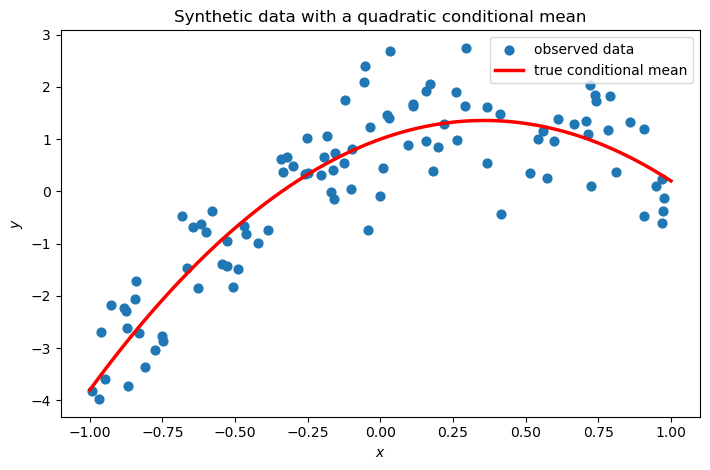

In [122]:
plt.figure(figsize=(7.2, 4.8))

plt.scatter(x, y, s=40, label="observed data")
plt.plot(grid, true_grid,  linewidth=2.5, color='red', label="true conditional mean")

plt.xlabel("$x$")
plt.ylabel("$y$")
plt.title("Synthetic data with a quadratic conditional mean")
plt.legend()
plt.tight_layout()
plt.show()


## 2. Fit increasingly flexible polynomial models

For polynomial degree \(p\),

$
\mu_p(x)
=
\beta_0+\beta_1x+\cdots+\beta_px^p.
$

The degree-\((p+1)\) model contains the degree-\(p\) model as a special case. Therefore,

$
\boxed{
\mathrm{RSS}_{p+1}\leq \mathrm{RSS}_p.
}
$

Consequently,

$
\boxed{
R^2_{p+1}\geq R^2_p.
}
$

This is why ordinary \(R^2\) cannot by itself determine when model complexity has become excessive.


In [123]:
degrees = np.arange(1, max_degree + 1)

rss_values = []
r2_values = []
adj_r2_values = []

models = {}

for degree in degrees:
    X = np.column_stack([x**j for j in range(1, degree + 1)])

    model = LinearRegression().fit(X, y)
    yhat = model.predict(X)

    rss = np.sum((y - yhat)**2)
    r2 = r2_score(y, yhat)

    # p = number of predictors, excluding the intercept
    adj_r2 = 1 - (1-r2)*(n-1)/(n-degree-1)

    rss_values.append(rss)
    r2_values.append(r2)
    adj_r2_values.append(adj_r2)
    models[degree] = model

rss_values = np.asarray(rss_values)
r2_values = np.asarray(r2_values)
adj_r2_values = np.asarray(adj_r2_values)

best_adj_degree = int(degrees[np.argmax(adj_r2_values)])

print(f"Best degree by adjusted R^2: {best_adj_degree}")


Best degree by adjusted R^2: 18


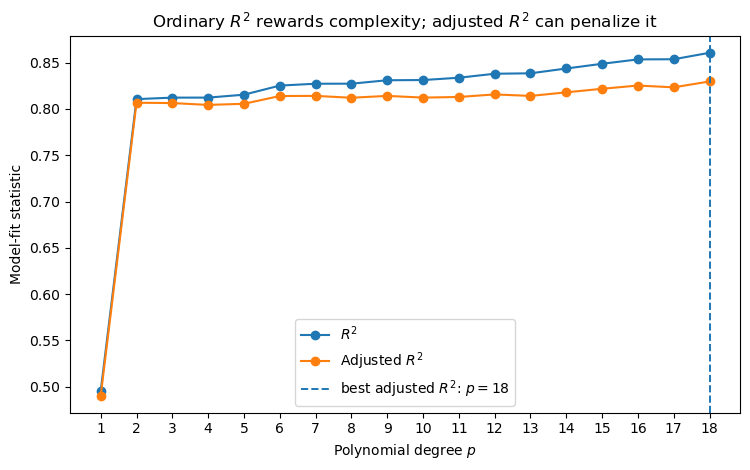

In [124]:
plt.figure(figsize=(7.6, 4.8))

plt.plot(degrees, r2_values, marker="o", label=r"$R^2$")
plt.plot(degrees, adj_r2_values, marker="o", label=r"Adjusted $R^2$")

plt.axvline(
    best_adj_degree,
    linestyle="--",
    linewidth=1.4,
    label=fr"best adjusted $R^2$: $p={best_adj_degree}$"
)

plt.xlabel("Polynomial degree $p$")
plt.ylabel("Model-fit statistic")
plt.title(r"Ordinary $R^2$ rewards complexity; adjusted $R^2$ can penalize it")
plt.xticks(degrees)
plt.legend()
plt.tight_layout()
plt.show()


## 3. From RSS to the maximized Gaussian likelihood

Assume

$
Y_i\mid x_i
\sim
\mathcal N(\mu_i,\sigma^2).
$

For a fixed polynomial degree \(p\), the log-likelihood is

$
\ell(\beta,\sigma^2)
=
-\frac n2\log(2\pi)
-\frac n2\log(\sigma^2)
-\frac{1}{2\sigma^2}\mathrm{RSS}(\beta).
$

At the MLE,

$
\hat\sigma^2
=
\frac{\mathrm{RSS}(\hat\beta)}{n}.
$

Substituting this into the log-likelihood gives

$
\boxed{
-2\hat\ell
=
n\left[
\log(2\pi)+1+
\log\left(\frac{\mathrm{RSS}}{n}\right)
\right].
}
$

For models fitted to the same dataset, the terms

$
n[\log(2\pi)+1]
$

are common to every model. Thus, for model comparison,

$
\boxed{
-2\hat\ell
\equiv
n\log\left(\frac{\mathrm{RSS}}{n}\right).
}
$

As RSS decreases, the maximized likelihood improves.


## 4. AIC and BIC

The information criteria add an explicit complexity penalty to the maximized likelihood:

$
\mathrm{AIC}
=
-2\hat\ell+2k,
$

$
\mathrm{BIC}
=
-2\hat\ell+k\log n.
$

Here \(k\) is the number of free parameters in the likelihood.

For a degree-\(p\) Gaussian polynomial regression,

$
\beta_0,\beta_1,\ldots,\beta_p
$

gives \(p+1\) regression coefficients, and \(\sigma^2\) is one additional parameter. Therefore,

$
\boxed{k=p+2.}
$

Both criteria are **minimized**.

AIC uses the penalty

$
2k,
$

while BIC uses

$
k\log n.
$

Since $\log n>2$ for $n>e^2$, BIC generally penalizes additional parameters more strongly than AIC.


In [125]:
aic_values = []
bic_values = []
neg2loglik_values = []
k_values = []

for degree, rss in zip(degrees, rss_values):

    # p+1 regression coefficients + one variance parameter
    k = degree + 2

    # Exact -2 maximized Gaussian log-likelihood
    neg2loglik = n * (
        np.log(2*np.pi)
        + 1
        + np.log(rss/n)
    )

    aic = neg2loglik + 2*k
    bic = neg2loglik + k*np.log(n)

    k_values.append(k)
    neg2loglik_values.append(neg2loglik)
    aic_values.append(aic)
    bic_values.append(bic)

aic_values = np.asarray(aic_values)
bic_values = np.asarray(bic_values)
neg2loglik_values = np.asarray(neg2loglik_values)

best_aic_degree = int(degrees[np.argmin(aic_values)])
best_bic_degree = int(degrees[np.argmin(bic_values)])

print(f"Best degree by adjusted R^2: {best_adj_degree}")
print(f"Best degree by AIC:          {best_aic_degree}")
print(f"Best degree by BIC:          {best_bic_degree}")


Best degree by adjusted R^2: 18
Best degree by AIC:          6
Best degree by BIC:          2


## 5. Compare the three criteria on the same candidate models

The three criteria use different numerical scales and different optimization directions:

\[
\begin{array}{ccl}
R^2_{\mathrm{adj}}
&:&
\text{maximize},
\\[1mm]
\mathrm{AIC}
&:&
\text{minimize},
\\[1mm]
\mathrm{BIC}
&:&
\text{minimize}.
\end{array}
\]

It is therefore clearer to display them in separate panels.


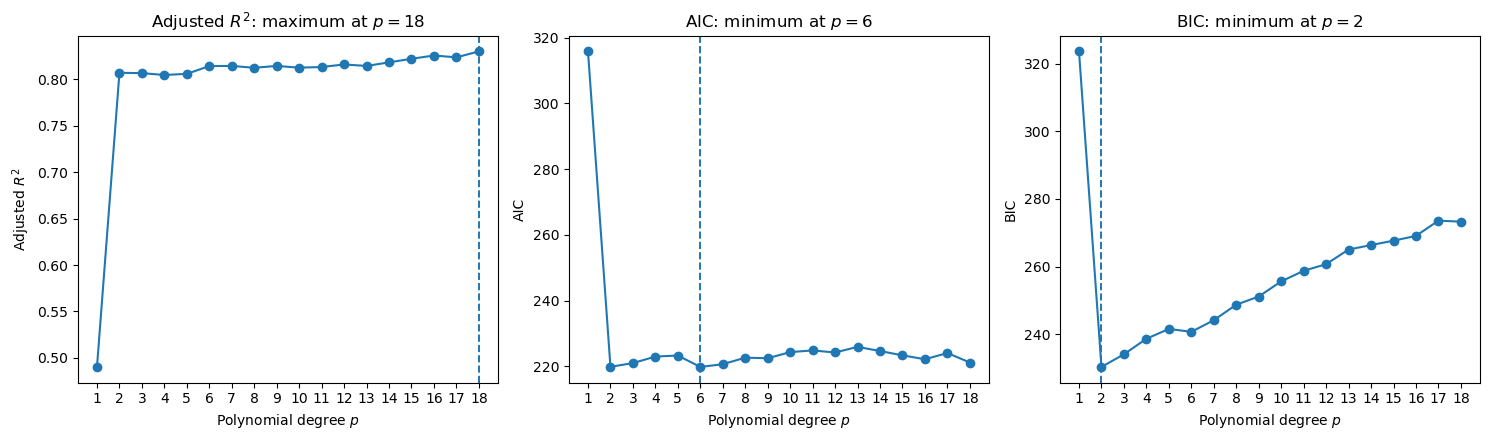

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Adjusted R^2
axes[0].plot(degrees, adj_r2_values, marker="o")
axes[0].axvline(best_adj_degree, linestyle="--", linewidth=1.4)
axes[0].set_xlabel("Polynomial degree $p$")
axes[0].set_ylabel(r"Adjusted $R^2$")
axes[0].set_title(fr"Adjusted $R^2$: maximum at $p={best_adj_degree}$")

# AIC
axes[1].plot(degrees, aic_values, marker="o")
axes[1].axvline(best_aic_degree, linestyle="--", linewidth=1.4)
axes[1].set_xlabel("Polynomial degree $p$")
axes[1].set_ylabel("AIC")
axes[1].set_title(fr"AIC: minimum at $p={best_aic_degree}$")

# BIC
axes[2].plot(degrees, bic_values, marker="o")
axes[2].axvline(best_bic_degree, linestyle="--", linewidth=1.4)
axes[2].set_xlabel("Polynomial degree $p$")
axes[2].set_ylabel("BIC")
axes[2].set_title(fr"BIC: minimum at $p={best_bic_degree}$")

for ax in axes:
    ax.set_xticks(degrees)

plt.tight_layout()
plt.savefig('AIC+BIC.png',dpi=300)


### Interpretation

The training fit continues to improve as the polynomial degree increases because

$
\mathrm{RSS}_{p+1}\leq \mathrm{RSS}_p.
$

AIC and BIC do **not** ask whether the larger model fits better; it necessarily can.

Instead they ask whether the improvement in maximized likelihood is large enough to justify the additional parameters.

$
\boxed{
\text{better fit}
\qquad\text{versus}\qquad
\text{greater complexity}.
}
$


## 6. Why can AIC or BIC increase even when RSS decreases?

Separate each information criterion into two pieces.

For AIC,

$
\mathrm{AIC}
=
\underbrace{-2\hat\ell}_{\text{lack of fit}}
+
\underbrace{2k}_{\text{complexity penalty}}.
$

For BIC,

$
\mathrm{BIC}
=
\underbrace{-2\hat\ell}_{\text{lack of fit}}
+
\underbrace{k\log n}_{\text{complexity penalty}}.
$

As polynomial degree increases,

$
-2\hat\ell
$

tends to decrease because the fit improves.

At the same time,

$
2k
\quad\text{and}\quad
k\log n
$

increase because more parameters are being estimated.

The information criterion reaches its minimum when further improvements in fit no longer compensate for the increased complexity.


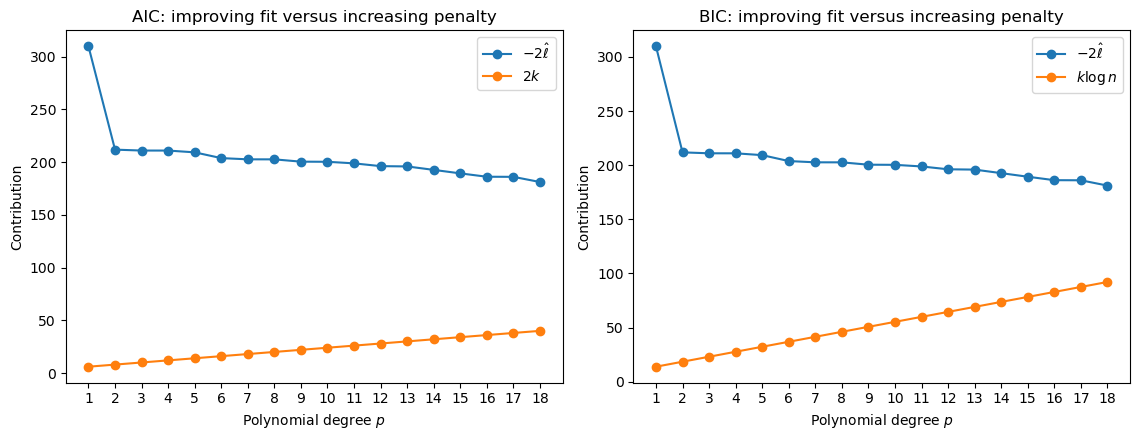

In [127]:
aic_penalty = 2*np.asarray(k_values)
bic_penalty = np.asarray(k_values)*np.log(n)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))

axes[0].plot(degrees, neg2loglik_values, marker="o", label=r"$-2\hat\ell$")
axes[0].plot(degrees, aic_penalty, marker="o", label=r"$2k$")
axes[0].set_xlabel("Polynomial degree $p$")
axes[0].set_ylabel("Contribution")
axes[0].set_title("AIC: improving fit versus increasing penalty")
axes[0].legend()

axes[1].plot(degrees, neg2loglik_values, marker="o", label=r"$-2\hat\ell$")
axes[1].plot(degrees, bic_penalty, marker="o", label=r"$k\log n$")
axes[1].set_xlabel("Polynomial degree $p$")
axes[1].set_ylabel("Contribution")
axes[1].set_title("BIC: improving fit versus increasing penalty")
axes[1].legend()

for ax in axes:
    ax.set_xticks(degrees)

plt.tight_layout()
plt.show()


## 7. Compare the selected fitted curves

We now compare:

- the true conditional mean;
- the degree selected by adjusted \(R^2\);
- the degree selected by AIC;
- the degree selected by BIC;
- a deliberately overfit degree-18 model.

This translates the numerical criteria back into the fitted regression functions.


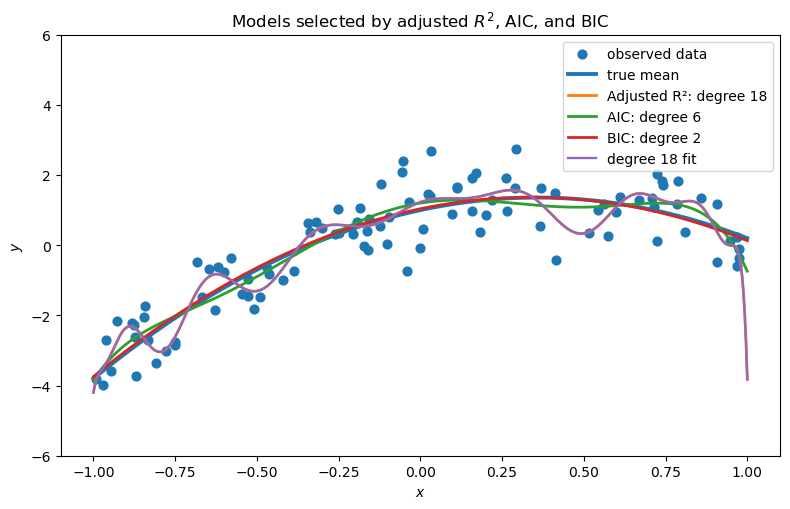

In [128]:
def polynomial_predict(model, degree, x_new):
    X_new = np.column_stack([x_new**j for j in range(1, degree + 1)])
    return model.predict(X_new)

selected_degrees = {
    "Adjusted R²": best_adj_degree,
    "AIC": best_aic_degree,
    "BIC": best_bic_degree,
}

plt.figure(figsize=(8, 5.2))

plt.scatter(x, y, s=40, label="observed data")
plt.plot(grid, true_grid, linewidth=2.8, label="true mean")

for label, degree in selected_degrees.items():
    plt.plot(
        grid,
        polynomial_predict(models[degree], degree, grid),
        linewidth=2,
        label=f"{label}: degree {degree}"
    )

plt.plot(
    grid,
    polynomial_predict(models[18], 18, grid),
    linewidth=1.7,
    label="degree 18 fit"
)

plt.xlabel("$x$")
plt.ylabel("$y$")
plt.ylim(-6, 6)
plt.title("Models selected by adjusted $R^2$, AIC, and BIC")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Summary table

The next table makes the tradeoff explicit for every candidate polynomial degree.


In [129]:
summary = pd.DataFrame({
    "degree": degrees,
    "RSS": rss_values,
    "R2": r2_values,
    "adjusted_R2": adj_r2_values,
    "k": k_values,
    "-2logL": neg2loglik_values,
    "AIC": aic_values,
    "BIC": bic_values,
})

summary.round(3)


,degree,RSS,R2,adjusted_R2,k,-2logL,AIC,BIC
0,1,129.745,0.496,0.490,3,309.827,315.827,323.643
1,2,48.715,0.811,0.807,4,211.869,219.869,230.290
2,3,48.297,0.812,0.806,5,211.007,221.007,234.033
3,4,48.289,0.812,0.804,6,210.991,222.991,238.622
4,5,47.482,0.815,0.806,7,209.305,223.305,241.541
5,6,44.953,0.825,0.814,8,203.832,219.832,240.673
6,7,44.435,0.827,0.814,9,202.673,220.673,244.119
7,8,44.426,0.827,0.812,10,202.652,222.652,248.704
8,9,43.468,0.831,0.814,11,200.474,222.474,251.131
9,10,43.413,0.831,0.812,12,200.346,224.346,255.608


# Take-home message

All three corrected criteria are responses to the same fundamental problem:

$
\text{training fit automatically improves as model flexibility increases.}
$

Adjusted \(R^2\) handles this through a degrees-of-freedom correction:

$
R_{\mathrm{adj}}^2
=
1-
(1-R^2)\frac{n-1}{n-p-1}.
$

AIC and BIC instead begin from the maximized likelihood:

$
\mathrm{AIC}
=
-2\hat\ell+2k,
$

$
\mathrm{BIC}
=
-2\hat\ell+k\log n.
$

Thus the conceptual progression is

$
R^2
\;\longrightarrow\;
R^2_{\mathrm{adj}}
\;\longrightarrow\;
\text{likelihood}
\;\longrightarrow\;
\mathrm{AIC/BIC}.
$

The central model-selection principle is unchanged:

$
\text{additional complexity should be accepted only when it earns a sufficient improvement in fit.}
$
